[![Roboflow Notebooks](https://media.roboflow.com/notebooks/template/bannertest2-2.png?ik-sdk-version=javascript-1.4.3&updatedAt=1672932710194)](https://github.com/roboflow/notebooks)

# How to Train YOLO26 Object Detection on a Custom Dataset

---

[![roboflow](https://raw.githubusercontent.com/roboflow-ai/notebooks/main/assets/badges/roboflow-blogpost.svg)](https://blog.roboflow.com/how-to-train-yolo26-custom-data/) [![GitHub](https://badges.aleen42.com/src/github.svg)](https://github.com/ultralytics/ultralytics)

YOLO26 introduces a unified architecture designed to support detection, segmentation, and pose tasks within a single model family. The model uses an anchor-free design with a decoupled head.

## Setup

### Configure API keys

To fine-tune YOLO26, you need to provide your Roboflow API key. Follow these steps:

- Go to your [`Roboflow Settings`](https://app.roboflow.com/settings/api) page. Click `Copy`. This will place your private key in the clipboard.
- In Colab, go to the left pane and click on `Secrets` (🔑). Store Roboflow API Key under the name `ROBOFLOW_API_KEY`.

### Before you start

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Runtime` -> `Change runtime type` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [4]:
!nvidia-smi

Thu Oct 29 07:47:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

**NOTE:** To make it easier for us to manage datasets, images and models we create a `HOME` constant.

In [5]:
import os
HOME = os.getcwd()
print(HOME)

/content


### Install dependencies required for YOLO26

In [6]:
%pip install -q "ultralytics>=8.4.0" supervision roboflow

# prevent ultralytics from tracking your activity
!yolo settings sync=False
import ultralytics
ultralytics.checks()

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.8/112.6 GB disk)


In [7]:
from google.colab import userdata
from roboflow import Roboflow

# 從 Colab Secrets 安全取得 API Key
api_key = userdata.get("ROBOFLOW_API_KEY")

# 登入 Roboflow
rf = Roboflow(api_key=api_key)

print("Roboflow 連線成功！")

Roboflow 連線成功！


In [8]:
project = rf.workspace("-qnknw").project("table-tennis-racket-xppyf-ggnqa-uzoiq")
version = project.version(1)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Table-tennis-racket-1 in yolo26:: 100%|██████████| 2632/2632 [00:00<00:00, 3742.24it/s]


In [9]:
import os

# 顯示 Roboflow 把 Dataset 放在哪裡
print("Dataset 路徑：", dataset.location)

print("\n資料夾內容：")

for item in os.listdir(dataset.location):
    print("-", item)

Dataset 路徑： /content/Table-tennis-racket-1

資料夾內容：
- data.yaml
- README.roboflow.txt
- valid
- test
- train


In [10]:
# 查看 data.yaml 內容

yaml_path = os.path.join(
    dataset.location,
    "data.yaml"
)

with open(yaml_path, "r", encoding="utf-8") as f:
    print(f.read())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['paddle']

roboflow:
  workspace: -qnknw
  project: table-tennis-racket-xppyf-ggnqa-uzoiq
  version: 1
  license: CC BY 4.0
  url: https://app.roboflow.com/-qnknw/table-tennis-racket-xppyf-ggnqa-uzoiq/1


In [11]:
from ultralytics import YOLO

# 載入 YOLO26 Nano 預訓練模型
model = YOLO("yolo26n.pt")

# 開始訓練我們的 paddle Dataset
results = model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/runs",
    name="paddle_baseline_v1"
)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Table-tennis-racket-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=paddle_baseline_v1, nbs=64, nms=None, opset=None

In [12]:
from ultralytics import YOLO

# 載入剛剛訓練好的最佳模型
paddle_model = YOLO(
    "/content/runs/paddle_baseline_v1/weights/best.pt"
)

print("Paddle 模型載入成功！")

Paddle 模型載入成功！


In [10]:
from google.colab import files

uploaded = files.upload()

test_image = list(uploaded.keys())[0]

print("測試圖片：", test_image)

Saving 1688eee1-1f4a-40cc-9276-06257ab93238.webp to 1688eee1-1f4a-40cc-9276-06257ab93238.webp
測試圖片： 1688eee1-1f4a-40cc-9276-06257ab93238.webp


In [11]:
# 使用我們自己的 Paddle 模型進行辨識

results = paddle_model.predict(
    source=test_image,
    conf=0.25,
    save=True
)

print("辨識完成！")


image 1/1 /content/1688eee1-1f4a-40cc-9276-06257ab93238.webp: 640x640 3 paddles, 10.3ms
Speed: 2.2ms preprocess, 10.3ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
辨識完成！


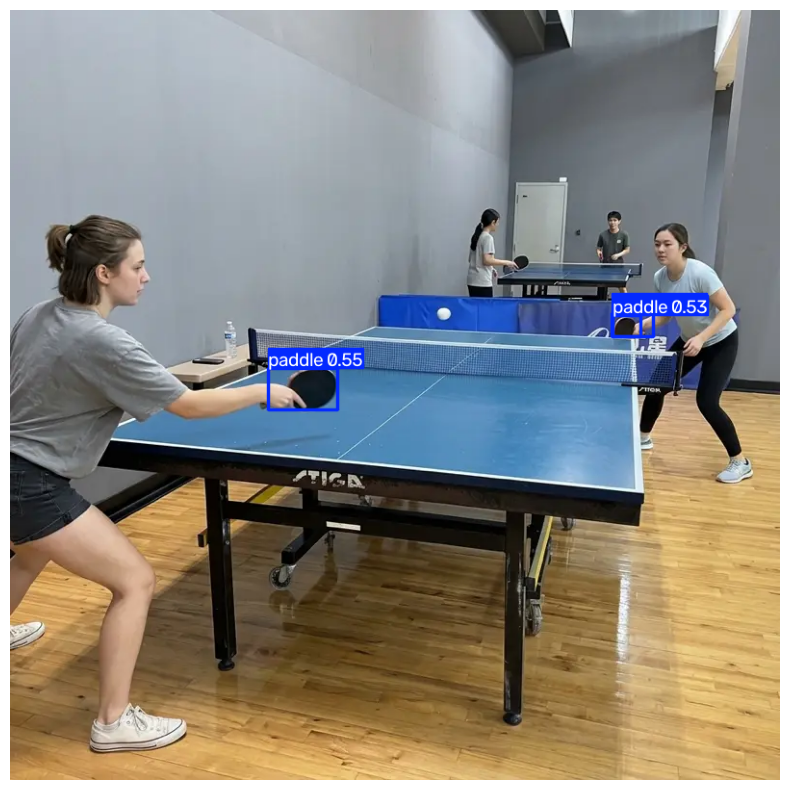

In [13]:
import matplotlib.pyplot as plt
import cv2

annotated_frame = results[0].plot()

annotated_frame = cv2.cvtColor(
    annotated_frame,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 10))
plt.imshow(annotated_frame)
plt.axis("off")
plt.show()

In [14]:
from google.colab import files

uploaded = files.upload()

video_name = list(uploaded.keys())[0]

print("影片：", video_name)

Saving istockphoto-908086498-640_adpp_is.mp4 to istockphoto-908086498-640_adpp_is.mp4
影片： istockphoto-908086498-640_adpp_is.mp4


In [15]:
# 使用我們剛剛訓練好的 paddle 模型跑影片

video_results = paddle_model.predict(
    source=video_name,
    conf=0.25,
    save=True
)

print("影片分析完成！")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/384) /content/istockphoto-908086498-640_adpp_is.mp4: 384x640 (no detections), 61.0ms
video 1/1 (frame 2/384) /content/istockphoto-908086498-640_adpp_is.mp4: 384x640 (no detections), 16.3ms
video 1/1 (frame 3/384) /content/istockphoto-908086498-640_adpp_is.mp4: 384x640 (no detections), 12.9ms
video 1/1 (frame 4/384) /content/istockphoto-908086498-640_adpp_is.mp4: 384x640 (no detections), 11.0ms
video 1/1 (frame 5/384) /content/istockphot

In [16]:
import os

output_dir = "/content/runs/detect/predict"

for file in os.listdir(output_dir):
    print(file)

1688eee1-1f4a-40cc-9276-06257ab93238.jpg
istockphoto-908086498-640_adpp_is.avi


In [17]:
import subprocess
import os

# 自動找 predict 資料夾裡的影片
video_files = [
    f for f in os.listdir(output_dir)
    if f.endswith((".mp4", ".avi", ".mov"))
]

result_video = os.path.join(
    output_dir,
    video_files[0]
)

final_video = "/content/paddle_test_final.mp4"

subprocess.run([
    "ffmpeg",
    "-y",
    "-i", result_video,
    "-vcodec", "libx264",
    "-pix_fmt", "yuv420p",
    final_video
])

print("完成：", final_video)

完成： /content/paddle_test_final.mp4


In [17]:
from IPython.display import Video

Video(
    "/content/paddle_test_final.mp4",
    embed=True
)

In [24]:
from google.colab import files

uploaded = files.upload()

video_name = list(uploaded.keys())[0]

print("影片：", video_name)

Saving istockphoto-487408818-640_adpp_is.mp4 to istockphoto-487408818-640_adpp_is.mp4
影片： istockphoto-487408818-640_adpp_is.mp4


In [29]:
# ============================================================
# Table Tennis Player Tracking
#
# Paddle Detection
#        +
# YOLO Pose
#        +
# ByteTrack
#        ↓
# Paddle ↔ Wrist
#        ↓
# Lock PLAYER ID
#        ↓
# Shoulder Center
#        ↓
# RAW X
#        ↓
# EMA Smooth
#        ↓
# PLAYER ID Recovery
# ============================================================


import cv2
import os
import glob
import math
import subprocess

from ultralytics import YOLO


# ============================================================
# 0. 自動尋找輸入影片
# ============================================================

video_files = []

for pattern in [
    "/content/*.mp4",
    "/content/*.MP4",
    "/content/*.mov",
    "/content/*.MOV",
    "/content/*.avi",
    "/content/*.AVI",
    "/content/*.mkv",
    "/content/*.MKV"
]:

    video_files.extend(
        glob.glob(pattern)
    )


exclude_names = {
    "player_input.mp4",
    "player_tracking_raw.mp4",
    "player_tracking_final.mp4"
}


video_files = [
    path
    for path in video_files
    if os.path.basename(path)
    not in exclude_names
]


if len(video_files) == 0:

    raise FileNotFoundError(
        "❌ /content 找不到測試影片"
    )


video_name = max(
    video_files,
    key=os.path.getmtime
)


print("================================")
print("輸入影片：")
print(video_name)
print("================================")


# ============================================================
# 1. 模型
# ============================================================

PADDLE_MODEL_PATH = (
    "/content/runs/paddle_baseline_v1/weights/best.pt"
)


if not os.path.exists(
    PADDLE_MODEL_PATH
):

    raise FileNotFoundError(
        "❌ 找不到 Paddle best.pt"
    )


paddle_model = YOLO(
    PADDLE_MODEL_PATH
)


pose_model = YOLO(
    "yolo26n-pose.pt"
)


print("Paddle model 載入成功")
print("Pose model 載入成功")


# ============================================================
# 2. 系統設定
# ============================================================

PADDLE_CONF = 0.25

POSE_CONF = 0.30

WRIST_CONF = 0.25

BODY_KP_CONF = 0.30


# Paddle ↔ Wrist 最大距離比例
MAX_WRIST_DISTANCE_RATIO = 0.25


# 第一次認定 PLAYER
# 至少需要幾次球拍證據
CONFIRM_SCORE = 3


# EMA
EMA_ALPHA = 0.30


# ============================================================
# Recovery 設定
# ============================================================

# PLAYER 消失至少幾 Frame
# 才開始嘗試換 ID
#
# 避免只漏一幀就亂換人
RECOVERY_START_FRAMES = 3


# 最多嘗試 Recovery 幾秒
RECOVERY_MAX_SECONDS = 2.0


# Recovery 候選人 bbox 面積
# 與原 PLAYER 可以差多少
RECOVERY_AREA_MIN = 0.40

RECOVERY_AREA_MAX = 2.50


TARGET_ZONE = "ANY"


# ============================================================
# 3. 安全轉換影片
# ============================================================

converted_video = (
    "/content/player_input.mp4"
)


if os.path.exists(
    converted_video
):

    os.remove(
        converted_video
    )


ffmpeg_result = subprocess.run(
    [
        "ffmpeg",
        "-y",
        "-i",
        video_name,

        "-an",

        "-c:v",
        "libx264",

        "-preset",
        "fast",

        "-crf",
        "20",

        "-pix_fmt",
        "yuv420p",

        "-movflags",
        "+faststart",

        converted_video
    ],

    stdout=subprocess.PIPE,

    stderr=subprocess.PIPE,

    text=True
)


if ffmpeg_result.returncode != 0:

    print(
        ffmpeg_result.stderr[-3000:]
    )

    raise RuntimeError(
        "❌ FFmpeg 轉檔失敗"
    )


print("✅ 影片轉檔成功")


# ============================================================
# 4. OpenCV 開啟影片
# ============================================================

cap = cv2.VideoCapture(
    converted_video
)


if not cap.isOpened():

    cap.release()

    cap = cv2.VideoCapture(
        video_name
    )


if not cap.isOpened():

    raise RuntimeError(
        "❌ OpenCV 無法開啟影片"
    )


width = int(
    cap.get(
        cv2.CAP_PROP_FRAME_WIDTH
    )
)


height = int(
    cap.get(
        cv2.CAP_PROP_FRAME_HEIGHT
    )
)


fps = cap.get(
    cv2.CAP_PROP_FPS
)


total_frames = int(
    cap.get(
        cv2.CAP_PROP_FRAME_COUNT
    )
)


if fps <= 0:

    fps = 30


RECOVERY_MAX_FRAMES = int(
    fps
    *
    RECOVERY_MAX_SECONDS
)


print("")
print("============================")
print(
    "影片尺寸：",
    width,
    "x",
    height
)
print(
    "FPS：",
    fps
)
print(
    "Frames：",
    total_frames
)
print(
    "Recovery Max Frames：",
    RECOVERY_MAX_FRAMES
)
print("============================")


# ============================================================
# 5. 輸出影片
# ============================================================

raw_output = (
    "/content/player_tracking_raw.mp4"
)


fourcc = cv2.VideoWriter_fourcc(
    *"mp4v"
)


writer = cv2.VideoWriter(
    raw_output,
    fourcc,
    fps,
    (
        width,
        height
    )
)


if not writer.isOpened():

    raise RuntimeError(
        "❌ 無法建立輸出影片"
    )


# ============================================================
# 6. 工具函數
# ============================================================

def distance(
    p1,
    p2
):

    return math.sqrt(
        (p1[0] - p2[0]) ** 2
        +
        (p1[1] - p2[1]) ** 2
    )


# ============================================================

def inside_expanded_bbox(
    point,
    bbox,
    margin=0.20
):

    px, py = point

    x1, y1, x2, y2 = bbox


    w = x2 - x1

    h = y2 - y1


    x1 -= w * margin

    x2 += w * margin

    y1 -= h * margin

    y2 += h * margin


    return (
        x1 <= px <= x2
        and
        y1 <= py <= y2
    )


# ============================================================

def in_target_zone(
    center_x
):

    if TARGET_ZONE == "LEFT":

        return (
            center_x
            <
            width / 2
        )


    elif TARGET_ZONE == "RIGHT":

        return (
            center_x
            >=
            width / 2
        )


    return True


# ============================================================

def kp_conf(
    data
):

    if len(data) >= 3:

        return float(
            data[2]
        )


    return 1.0


# ============================================================
# PLAYER 定位來源
#
# 優先：
#
# Shoulder
# ↓
# Hip
# ↓
# BBox
# ============================================================

def get_player_center(
    person
):

    shoulder_ok = (

        person[
            "left_shoulder_conf"
        ]
        >=
        BODY_KP_CONF

        and

        person[
            "right_shoulder_conf"
        ]
        >=
        BODY_KP_CONF
    )


    if shoulder_ok:

        left = person[
            "left_shoulder"
        ]

        right = person[
            "right_shoulder"
        ]


        center = (

            int(
                (
                    left[0]
                    +
                    right[0]
                )
                /
                2
            ),

            int(
                (
                    left[1]
                    +
                    right[1]
                )
                /
                2
            )
        )


        return (
            center,
            "SHOULDERS"
        )


    # ========================================================
    # Shoulder 不行 → Hip
    # ========================================================

    hip_ok = (

        person[
            "left_hip_conf"
        ]
        >=
        BODY_KP_CONF

        and

        person[
            "right_hip_conf"
        ]
        >=
        BODY_KP_CONF
    )


    if hip_ok:

        left = person[
            "left_hip"
        ]

        right = person[
            "right_hip"
        ]


        center = (

            int(
                (
                    left[0]
                    +
                    right[0]
                )
                /
                2
            ),

            int(
                (
                    left[1]
                    +
                    right[1]
                )
                /
                2
            )
        )


        return (
            center,
            "HIPS"
        )


    # ========================================================
    # 最後退回 BBox
    # ========================================================

    return (
        person[
            "bbox_center"
        ],
        "BBOX"
    )


# ============================================================
# Recovery Candidate
#
# 使用：
#
# 1. 與最後 PLAYER 位置距離
# 2. BBox 大小
# 3. 是否有 Paddle 證據
#
# 判斷新 Track ID
# 是否其實是原來 PLAYER
# ============================================================

def find_recovery_candidate(
    people,
    last_center,
    last_bbox,
    evidence_ids
):

    if (
        last_center is None
        or
        last_bbox is None
    ):

        return None


    last_x1, last_y1, last_x2, last_y2 = (
        last_bbox
    )


    last_w = max(
        1,
        last_x2 - last_x1
    )


    last_h = max(
        1,
        last_y2 - last_y1
    )


    last_area = max(
        1,
        last_w * last_h
    )


    # --------------------------------------------------------
    # Recovery 搜尋範圍
    #
    # 根據上一個 PLAYER bbox 大小
    # 動態決定允許移動多少
    # --------------------------------------------------------

    max_dx = max(
        70,
        min(
            width * 0.28,
            last_w * 2.5
        )
    )


    max_dy = max(
        70,
        min(
            height * 0.30,
            last_h * 1.0
        )
    )


    best_candidate = None

    best_score = float(
        "inf"
    )


    for person in people:

        candidate_center, source = (
            get_player_center(
                person
            )
        )


        cx, cy = candidate_center

        lx, ly = last_center


        dx = abs(
            cx - lx
        )


        dy = abs(
            cy - ly
        )


        # 太遠直接排除
        if dx > max_dx:

            continue


        if dy > max_dy:

            continue


        x1, y1, x2, y2 = (
            person[
                "bbox"
            ]
        )


        candidate_area = max(
            1,
            (
                x2 - x1
            )
            *
            (
                y2 - y1
            )
        )


        area_ratio = (
            candidate_area
            /
            last_area
        )


        # 人物大小差太多
        if (
            area_ratio
            <
            RECOVERY_AREA_MIN
        ):

            continue


        if (
            area_ratio
            >
            RECOVERY_AREA_MAX
        ):

            continue


        # ----------------------------------------------------
        # Recovery Score
        #
        # 越低越像原本 PLAYER
        # ----------------------------------------------------

        position_score = (
            dx / max_dx
            +
            0.6
            *
            (
                dy / max_dy
            )
        )


        size_score = (
            abs(
                math.log(
                    area_ratio
                )
            )
            *
            0.35
        )


        score = (
            position_score
            +
            size_score
        )


        # ----------------------------------------------------
        # 如果這個人此時剛好有持拍證據
        #
        # 很可能就是原 PLAYER
        # ----------------------------------------------------

        if (
            person["id"]
            in
            evidence_ids
        ):

            score -= 0.35


        # BBox fallback 稍微降低信任
        if source == "BBOX":

            score += 0.15


        if score < best_score:

            best_score = score

            best_candidate = person


    return best_candidate


# ============================================================
# 7. 系統狀態
# ============================================================

PLAYER_ID = None


player_scores = {}


player_lost_frames = 0


smooth_player_x = None


# ------------------------------------------------------------
# Recovery 記憶
# ------------------------------------------------------------

last_player_center = None

last_player_bbox = None


# 顯示 Recovery 成功訊息
recovery_notice_frames = 0

recovery_notice_text = ""


frame_count = 0


# ============================================================
# 8. 主迴圈
# ============================================================

while cap.isOpened():

    ret, frame = cap.read()


    if not ret:

        break


    # ========================================================
    # 畫面中央線
    # ========================================================

    cv2.line(
        frame,

        (
            width // 2,
            0
        ),

        (
            width // 2,
            height
        ),

        (
            255,
            255,
            255
        ),

        2
    )


    # ========================================================
    # A. Pose + ByteTrack
    # ========================================================

    pose_result = pose_model.track(
        source=frame,

        persist=True,

        tracker="bytetrack.yaml",

        conf=POSE_CONF,

        verbose=False
    )[0]


    # ========================================================
    # B. Paddle
    # ========================================================

    paddle_result = paddle_model.predict(
        source=frame,

        conf=PADDLE_CONF,

        verbose=False
    )[0]


    # ========================================================
    # C. Paddle 資料
    # ========================================================

    paddles = []


    if paddle_result.boxes is not None:

        for box in paddle_result.boxes:

            x1, y1, x2, y2 = (
                box.xyxy[0]
                .cpu()
                .numpy()
            )


            conf = float(
                box.conf[0]
            )


            x1 = int(x1)

            y1 = int(y1)

            x2 = int(x2)

            y2 = int(y2)


            cx = (
                x1 + x2
            ) // 2


            cy = (
                y1 + y2
            ) // 2


            paddles.append(
                {
                    "center": (
                        cx,
                        cy
                    ),

                    "bbox": (
                        x1,
                        y1,
                        x2,
                        y2
                    ),

                    "conf":
                        conf
                }
            )


            cv2.rectangle(
                frame,

                (
                    x1,
                    y1
                ),

                (
                    x2,
                    y2
                ),

                (
                    255,
                    0,
                    0
                ),

                3
            )


            cv2.putText(
                frame,

                f"PADDLE {conf:.2f}",

                (
                    x1,
                    max(
                        20,
                        y1 - 8
                    )
                ),

                cv2.FONT_HERSHEY_SIMPLEX,

                0.60,

                (
                    255,
                    0,
                    0
                ),

                2
            )


    # ========================================================
    # D. Person + Pose
    # ========================================================

    people = []


    if (
        pose_result.boxes is not None

        and

        pose_result.boxes.id is not None

        and

        pose_result.keypoints is not None
    ):

        boxes = (
            pose_result.boxes.xyxy
            .cpu()
            .numpy()
        )


        track_ids = (
            pose_result.boxes.id
            .int()
            .cpu()
            .tolist()
        )


        keypoints = (
            pose_result.keypoints.data
            .cpu()
            .numpy()
        )


        for i, (
            box,
            track_id
        ) in enumerate(
            zip(
                boxes,
                track_ids
            )
        ):

            x1, y1, x2, y2 = map(
                int,
                box
            )


            bbox_center = (

                (
                    x1 + x2
                )
                // 2,

                (
                    y1 + y2
                )
                // 2
            )


            # ------------------------------------------------
            # COCO Pose
            #
            # 5  Left Shoulder
            # 6  Right Shoulder
            #
            # 9  Left Wrist
            # 10 Right Wrist
            #
            # 11 Left Hip
            # 12 Right Hip
            # ------------------------------------------------

            ls_data = keypoints[i][5]

            rs_data = keypoints[i][6]

            lw_data = keypoints[i][9]

            rw_data = keypoints[i][10]

            lh_data = keypoints[i][11]

            rh_data = keypoints[i][12]


            people.append(
                {
                    "id":
                        track_id,

                    "bbox": (
                        x1,
                        y1,
                        x2,
                        y2
                    ),

                    "bbox_center":
                        bbox_center,

                    "left_shoulder": (
                        int(ls_data[0]),
                        int(ls_data[1])
                    ),

                    "right_shoulder": (
                        int(rs_data[0]),
                        int(rs_data[1])
                    ),

                    "left_shoulder_conf":
                        kp_conf(
                            ls_data
                        ),

                    "right_shoulder_conf":
                        kp_conf(
                            rs_data
                        ),

                    "left_wrist": (
                        int(lw_data[0]),
                        int(lw_data[1])
                    ),

                    "right_wrist": (
                        int(rw_data[0]),
                        int(rw_data[1])
                    ),

                    "left_wrist_conf":
                        kp_conf(
                            lw_data
                        ),

                    "right_wrist_conf":
                        kp_conf(
                            rw_data
                        ),

                    "left_hip": (
                        int(lh_data[0]),
                        int(lh_data[1])
                    ),

                    "right_hip": (
                        int(rh_data[0]),
                        int(rh_data[1])
                    ),

                    "left_hip_conf":
                        kp_conf(
                            lh_data
                        ),

                    "right_hip_conf":
                        kp_conf(
                            rh_data
                        )
                }
            )


    # ========================================================
    # E. Paddle ↔ Wrist
    # ========================================================

    evidence_ids = set()


    for paddle in paddles:

        paddle_center = (
            paddle[
                "center"
            ]
        )


        best_person = None

        best_wrist = None

        best_ratio = float(
            "inf"
        )


        for person in people:

            bbox = (
                person[
                    "bbox"
                ]
            )


            bbox_center_x = (
                person[
                    "bbox_center"
                ][0]
            )


            if not in_target_zone(
                bbox_center_x
            ):

                continue


            if not inside_expanded_bbox(
                paddle_center,
                bbox
            ):

                continue


            x1, y1, x2, y2 = bbox


            bbox_diag = math.sqrt(
                (x2 - x1) ** 2
                +
                (y2 - y1) ** 2
            )


            if bbox_diag <= 0:

                continue


            # ------------------------------------------------
            # Left Wrist
            # ------------------------------------------------

            if (
                person[
                    "left_wrist_conf"
                ]
                >=
                WRIST_CONF
            ):

                d = distance(
                    paddle_center,

                    person[
                        "left_wrist"
                    ]
                )


                ratio = (
                    d
                    /
                    bbox_diag
                )


                if ratio < best_ratio:

                    best_ratio = ratio

                    best_person = person

                    best_wrist = (
                        person[
                            "left_wrist"
                        ]
                    )


            # ------------------------------------------------
            # Right Wrist
            # ------------------------------------------------

            if (
                person[
                    "right_wrist_conf"
                ]
                >=
                WRIST_CONF
            ):

                d = distance(
                    paddle_center,

                    person[
                        "right_wrist"
                    ]
                )


                ratio = (
                    d
                    /
                    bbox_diag
                )


                if ratio < best_ratio:

                    best_ratio = ratio

                    best_person = person

                    best_wrist = (
                        person[
                            "right_wrist"
                        ]
                    )


        if (
            best_person is not None

            and

            best_ratio
            <=
            MAX_WRIST_DISTANCE_RATIO
        ):

            track_id = (
                best_person[
                    "id"
                ]
            )


            evidence_ids.add(
                track_id
            )


            # 第一次搜尋 PLAYER 才顯示
            if PLAYER_ID is None:

                cv2.line(
                    frame,

                    paddle_center,

                    best_wrist,

                    (
                        0,
                        255,
                        255
                    ),

                    3
                )


                cv2.putText(
                    frame,

                    (
                        f"ID {track_id} "
                        f"HOLDING PADDLE"
                    ),

                    (
                        paddle_center[0],

                        max(
                            30,
                            paddle_center[1] - 25
                        )
                    ),

                    cv2.FONT_HERSHEY_SIMPLEX,

                    0.60,

                    (
                        0,
                        255,
                        255
                    ),

                    2
                )


    # ========================================================
    # F. 第一次找 PLAYER
    # ========================================================

    if PLAYER_ID is None:

        for track_id in evidence_ids:

            if track_id not in player_scores:

                player_scores[
                    track_id
                ] = 0


            player_scores[
                track_id
            ] += 1


        # 無持拍證據稍微扣分
        for track_id in list(
            player_scores.keys()
        ):

            if track_id not in evidence_ids:

                player_scores[
                    track_id
                ] = max(
                    0,

                    player_scores[
                        track_id
                    ]
                    -
                    0.25
                )


        if len(
            player_scores
        ) > 0:

            best_id = max(
                player_scores,

                key=
                    player_scores.get
            )


            best_score = (
                player_scores[
                    best_id
                ]
            )


            cv2.putText(
                frame,

                (
                    f"PLAYER CANDIDATE: "
                    f"ID {best_id} "
                    f"SCORE {best_score:.1f}"
                ),

                (
                    30,
                    60
                ),

                cv2.FONT_HERSHEY_SIMPLEX,

                0.80,

                (
                    0,
                    255,
                    255
                ),

                2
            )


            if (
                best_score
                >=
                CONFIRM_SCORE
            ):

                PLAYER_ID = (
                    best_id
                )


                player_lost_frames = 0


                smooth_player_x = None


                last_player_center = None

                last_player_bbox = None


                print(
                    f"PLAYER LOCKED → ID {PLAYER_ID}"
                )


    # ========================================================
    # G. 確認原 PLAYER ID 是否還存在
    # ========================================================

    current_player = None


    if PLAYER_ID is not None:

        for person in people:

            if (
                person["id"]
                ==
                PLAYER_ID
            ):

                current_player = person

                break


    # ========================================================
    # H. PLAYER 消失
    #
    # 開始 Recovery
    # ========================================================

    if (
        PLAYER_ID is not None
        and
        current_player is None
    ):

        player_lost_frames += 1


        # ----------------------------------------------------
        # 先容忍幾 Frame
        #
        # 避免一幀漏偵測就立即換 ID
        # ----------------------------------------------------

        if (
            player_lost_frames
            >=
            RECOVERY_START_FRAMES
        ):

            recovery_candidate = (
                find_recovery_candidate(
                    people,
                    last_player_center,
                    last_player_bbox,
                    evidence_ids
                )
            )


            # =================================================
            # Recovery 成功
            # =================================================

            if (
                recovery_candidate
                is not None
            ):

                old_id = PLAYER_ID

                new_id = (
                    recovery_candidate[
                        "id"
                    ]
                )


                # 只有 ID 不同才視為 Recovery
                if new_id != old_id:

                    PLAYER_ID = new_id


                    current_player = (
                        recovery_candidate
                    )


                    player_lost_frames = 0


                    recovery_notice_text = (
                        f"PLAYER RECOVERED: "
                        f"{old_id} -> {new_id}"
                    )


                    recovery_notice_frames = int(
                        fps * 1.5
                    )


                    print(
                        recovery_notice_text
                    )


        # ====================================================
        # Recovery 還沒成功
        # ====================================================

        if current_player is None:

            cv2.putText(
                frame,

                (
                    f"RECOVERING PLAYER... "
                    f"{player_lost_frames}/"
                    f"{RECOVERY_MAX_FRAMES}"
                ),

                (
                    30,
                    110
                ),

                cv2.FONT_HERSHEY_SIMPLEX,

                0.80,

                (
                    0,
                    165,
                    255
                ),

                3
            )


            # 保留最後 Smooth X
            if smooth_player_x is not None:

                cv2.putText(
                    frame,

                    (
                        f"HOLD X: "
                        f"{smooth_player_x:+.3f}"
                    ),

                    (
                        30,
                        150
                    ),

                    cv2.FONT_HERSHEY_SIMPLEX,

                    0.75,

                    (
                        0,
                        165,
                        255
                    ),

                    2
                )


            # =================================================
            # Recovery 失敗太久
            #
            # 才真正重新搜尋球拍玩家
            # =================================================

            if (
                player_lost_frames
                >
                RECOVERY_MAX_FRAMES
            ):

                print(
                    "PLAYER Recovery failed"
                )

                print(
                    "Searching paddle player again..."
                )


                PLAYER_ID = None


                player_scores = {}


                player_lost_frames = 0


                smooth_player_x = None


                last_player_center = None

                last_player_bbox = None


    # ========================================================
    # PLAYER 正常可見
    # ========================================================

    elif current_player is not None:

        player_lost_frames = 0


    # ========================================================
    # I. 畫所有人物
    # ========================================================

    for person in people:

        track_id = (
            person[
                "id"
            ]
        )


        x1, y1, x2, y2 = (
            person[
                "bbox"
            ]
        )


        # ====================================================
        # PLAYER
        # ====================================================

        if (
            PLAYER_ID is not None

            and

            track_id
            ==
            PLAYER_ID
        ):

            cv2.rectangle(
                frame,

                (
                    x1,
                    y1
                ),

                (
                    x2,
                    y2
                ),

                (
                    0,
                    255,
                    0
                ),

                4
            )


            cv2.putText(
                frame,

                f"PLAYER ID {track_id}",

                (
                    x1,

                    max(
                        30,
                        y1 - 10
                    )
                ),

                cv2.FONT_HERSHEY_SIMPLEX,

                0.80,

                (
                    0,
                    255,
                    0
                ),

                3
            )


            # =================================================
            # Shoulder / Hip / BBox center
            # =================================================

            (
                body_center,
                track_source
            ) = get_player_center(
                person
            )


            body_x = int(
                body_center[0]
            )


            body_y = int(
                body_center[1]
            )


            # ------------------------------------------------
            # 保存 Recovery 所需資訊
            # ------------------------------------------------

            last_player_center = (
                body_x,
                body_y
            )


            last_player_bbox = (
                x1,
                y1,
                x2,
                y2
            )


            # ------------------------------------------------
            # 定位點
            # ------------------------------------------------

            cv2.circle(
                frame,

                (
                    body_x,
                    body_y
                ),

                9,

                (
                    0,
                    255,
                    255
                ),

                -1
            )


            # ------------------------------------------------
            # Shoulder line
            # ------------------------------------------------

            if (
                track_source
                ==
                "SHOULDERS"
            ):

                ls = person[
                    "left_shoulder"
                ]

                rs = person[
                    "right_shoulder"
                ]


                cv2.circle(
                    frame,

                    ls,

                    6,

                    (
                        255,
                        255,
                        0
                    ),

                    -1
                )


                cv2.circle(
                    frame,

                    rs,

                    6,

                    (
                        255,
                        255,
                        0
                    ),

                    -1
                )


                cv2.line(
                    frame,

                    ls,

                    rs,

                    (
                        255,
                        255,
                        0
                    ),

                    2
                )


            # =================================================
            # RAW X
            # =================================================

            raw_player_x = (

                body_x
                -
                width / 2

            ) / (

                width / 2
            )


            raw_player_x = max(
                -1.0,

                min(
                    1.0,
                    raw_player_x
                )
            )


            # =================================================
            # EMA
            # =================================================

            if smooth_player_x is None:

                smooth_player_x = (
                    raw_player_x
                )


            else:

                smooth_player_x = (

                    EMA_ALPHA
                    *
                    raw_player_x

                    +

                    (
                        1
                        -
                        EMA_ALPHA
                    )
                    *
                    smooth_player_x
                )


            # =================================================
            # 顯示
            # =================================================

            cv2.putText(
                frame,

                (
                    f"TRACK SOURCE: "
                    f"{track_source}"
                ),

                (
                    30,
                    105
                ),

                cv2.FONT_HERSHEY_SIMPLEX,

                0.70,

                (
                    0,
                    255,
                    255
                ),

                2
            )


            cv2.putText(
                frame,

                (
                    f"RAW X: "
                    f"{raw_player_x:+.3f}"
                ),

                (
                    30,
                    140
                ),

                cv2.FONT_HERSHEY_SIMPLEX,

                0.75,

                (
                    0,
                    255,
                    0
                ),

                2
            )


            cv2.putText(
                frame,

                (
                    f"SMOOTH X: "
                    f"{smooth_player_x:+.3f}"
                ),

                (
                    30,
                    180
                ),

                cv2.FONT_HERSHEY_SIMPLEX,

                0.85,

                (
                    0,
                    255,
                    0
                ),

                3
            )


        # ====================================================
        # OTHER PERSON
        # ====================================================

        else:

            cv2.rectangle(
                frame,

                (
                    x1,
                    y1
                ),

                (
                    x2,
                    y2
                ),

                (
                    150,
                    150,
                    150
                ),

                1
            )


            cv2.putText(
                frame,

                f"ID {track_id}",

                (
                    x1,

                    max(
                        20,
                        y1 - 5
                    )
                ),

                cv2.FONT_HERSHEY_SIMPLEX,

                0.50,

                (
                    150,
                    150,
                    150
                ),

                1
            )


    # ========================================================
    # Recovery 成功訊息
    # ========================================================

    if recovery_notice_frames > 0:

        cv2.putText(
            frame,

            recovery_notice_text,

            (
                30,
                220
            ),

            cv2.FONT_HERSHEY_SIMPLEX,

            0.85,

            (
                0,
                255,
                255
            ),

            3
        )


        recovery_notice_frames -= 1


    # ========================================================
    # 尚未找到 PLAYER
    # ========================================================

    if PLAYER_ID is None:

        cv2.putText(
            frame,

            "SEARCHING FOR PLAYER...",

            (
                30,
                110
            ),

            cv2.FONT_HERSHEY_SIMPLEX,

            0.85,

            (
                0,
                165,
                255
            ),

            3
        )


    # ========================================================
    # J. 寫入影片
    # ========================================================

    writer.write(
        frame
    )


    frame_count += 1


    if (
        frame_count
        %
        100
        ==
        0
    ):

        print(
            f"{frame_count} / "
            f"{total_frames}"
        )


# ============================================================
# 9. 關閉
# ============================================================

cap.release()

writer.release()


print("")
print("============================")
print("影片處理完成")
print(
    "Final PLAYER ID:",
    PLAYER_ID
)
print(
    "Processed Frames:",
    frame_count
)
print("============================")


# ============================================================
# 10. 最終影片
# ============================================================

final_output = (
    "/content/player_tracking_final.mp4"
)


result = subprocess.run(
    [
        "ffmpeg",
        "-y",

        "-i",
        raw_output,

        "-c:v",
        "libx264",

        "-pix_fmt",
        "yuv420p",

        "-movflags",
        "+faststart",

        final_output
    ],

    stdout=subprocess.PIPE,

    stderr=subprocess.PIPE,

    text=True
)


if result.returncode != 0:

    print(
        result.stderr[-2000:]
    )

    raise RuntimeError(
        "❌ 最終影片轉換失敗"
    )


print("")
print(
    "✅ 最終影片：",
    final_output
)


try:

    from google.colab import files

    print("")
    print(
        "下載："
    )

    print(
        "files.download('/content/player_tracking_final.mp4')"
    )

except:

    pass

輸入影片：
/content/istockphoto-487408818-640_adpp_is.mp4
Paddle model 載入成功
Pose model 載入成功
✅ 影片轉檔成功

影片尺寸： 768 x 432
FPS： 29.97002997002997
Frames： 1011
Recovery Max Frames： 59
100 / 1011
200 / 1011
PLAYER LOCKED → ID 1
300 / 1011
400 / 1011
500 / 1011
PLAYER RECOVERED: 1 -> 9
600 / 1011
700 / 1011
800 / 1011
900 / 1011
1000 / 1011

影片處理完成
Final PLAYER ID: 9
Processed Frames: 1011

✅ 最終影片： /content/player_tracking_final.mp4

下載：
files.download('/content/player_tracking_final.mp4')


In [30]:
from IPython.display import Video

Video(
    "/content/player_tracking_final.mp4",
    embed=True
)

### Download example data

Downloads example images for testing. You can use these or replace them with your own images.

In [ ]:
!wget -q https://media.roboflow.com/notebooks/examples/dog-2.jpeg
!wget -q https://media.roboflow.com/notebooks/examples/dog-3.jpeg

## Inference with model pre-trained on COCO dataset

### CLI

**NOTE:** CLI requires no customization or Python code. You can simply run all tasks from the terminal with the yolo command.

In [ ]:
!yolo task=detect mode=predict model=yolo26m.pt source={HOME}/dog-2.jpeg save=True verbose=False

Ultralytics 8.4.6 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO26m summary (fused): 132 layers, 20,411,132 parameters, 0 gradients, 68.2 GFLOPs
Results saved to /content/runs/detect/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


**NOTE:** Result annotated image got saved in `{HOME}/runs/detect/predict/`. Let's display it.

In [ ]:
!ls -la {HOME}/runs/detect/predict/

total 420
drwxr-xr-x 2 root root   4096 Jan 20 22:52 .
drwxr-xr-x 3 root root   4096 Jan 20 22:52 ..
-rw-r--r-- 1 root root 420529 Jan 20 22:52 dog-2.jpg


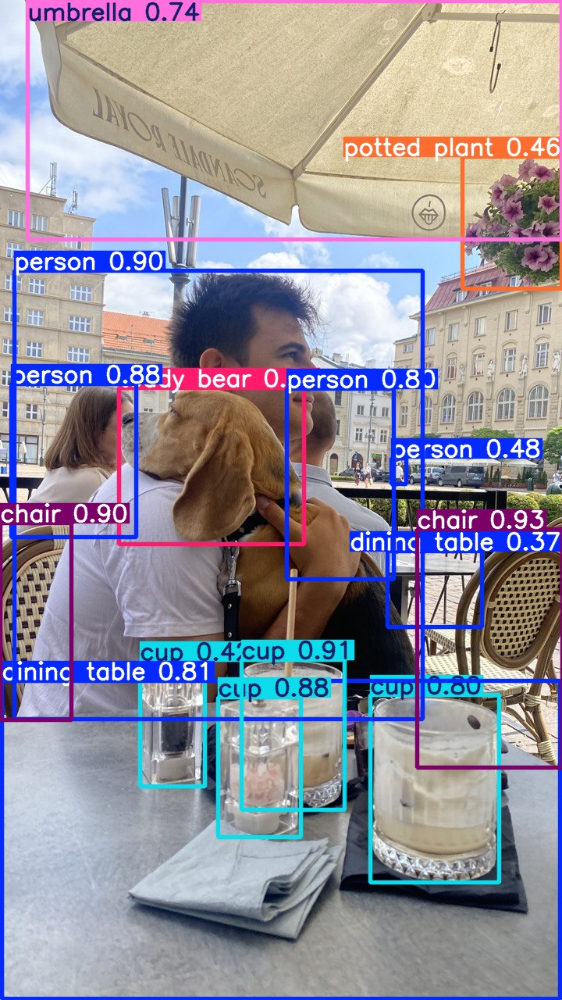

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/predict/dog-2.jpg', width=600)

### SDK

In [ ]:
from ultralytics import YOLO
from PIL import Image

model = YOLO('yolo26m.pt')
image = Image.open(f'{HOME}/dog-2.jpeg')
result = model.predict(image, verbose=False)[0]

**NOTE:** The obtained `result` object stores information about the location, classes, and confidence levels of the detected objects.

In [ ]:
result.boxes.xyxy

tensor([[5.3404e+02, 6.7770e+02, 7.2000e+02, 9.8270e+02],
        [3.0912e+02, 8.4417e+02, 4.4110e+02, 1.0363e+03],
        [5.4420e-01, 6.6944e+02, 9.1546e+01, 9.2108e+02],
        [1.8636e+01, 3.4667e+02, 5.4174e+02, 9.2046e+02],
        [2.7974e+02, 8.9215e+02, 3.8501e+02, 1.0716e+03],
        [1.4987e+01, 4.9126e+02, 1.7489e+02, 6.8704e+02],
        [2.8078e+00, 8.7185e+02, 7.1774e+02, 1.2785e+03],
        [3.6707e+02, 4.9763e+02, 5.0493e+02, 7.4178e+02],
        [4.7472e+02, 8.8993e+02, 6.4000e+02, 1.1297e+03],
        [3.5814e+01, 1.0317e+00, 7.1993e+02, 3.0651e+02],
        [5.0156e+02, 5.8670e+02, 5.2026e+02, 6.1997e+02],
        [5.9209e+02, 2.0039e+02, 7.1999e+02, 3.6992e+02],
        [1.7925e+02, 8.4660e+02, 2.6239e+02, 1.0062e+03],
        [4.9622e+02, 7.0596e+02, 6.1744e+02, 8.0277e+02],
        [1.5233e+02, 4.9656e+02, 3.8946e+02, 6.9643e+02]], device='cuda:0')

In [ ]:
result.boxes.conf

tensor([0.9344, 0.9107, 0.8983, 0.8982, 0.8838, 0.8816, 0.8050, 0.8048, 0.8017, 0.7403, 0.4840, 0.4638, 0.4220, 0.3653, 0.3069], device='cuda:0')

In [ ]:
result.boxes.cls

tensor([56., 41., 56.,  0., 41.,  0., 60.,  0., 41., 25.,  0., 58., 41., 60., 77.], device='cuda:0')

**NOTE:** YOLO26 can be easily integrated with `supervision` using the familiar `from_ultralytics` connector.

In [ ]:
import supervision as sv

detections = sv.Detections.from_ultralytics(result)

In [ ]:
import supervision as sv
from PIL import Image

def annotate(image: Image.Image, detections: sv.Detections) -> Image.Image:
    text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)

    box_annotator = sv.BoxAnnotator()
    label_annotator = sv.LabelAnnotator(
        text_color=sv.Color.BLACK,
        text_scale=text_scale,
        smart_position=True
    )

    out = image.copy()
    out = box_annotator.annotate(out, detections)
    out = label_annotator.annotate(out, detections)
    out.thumbnail((1000, 1000))
    return out

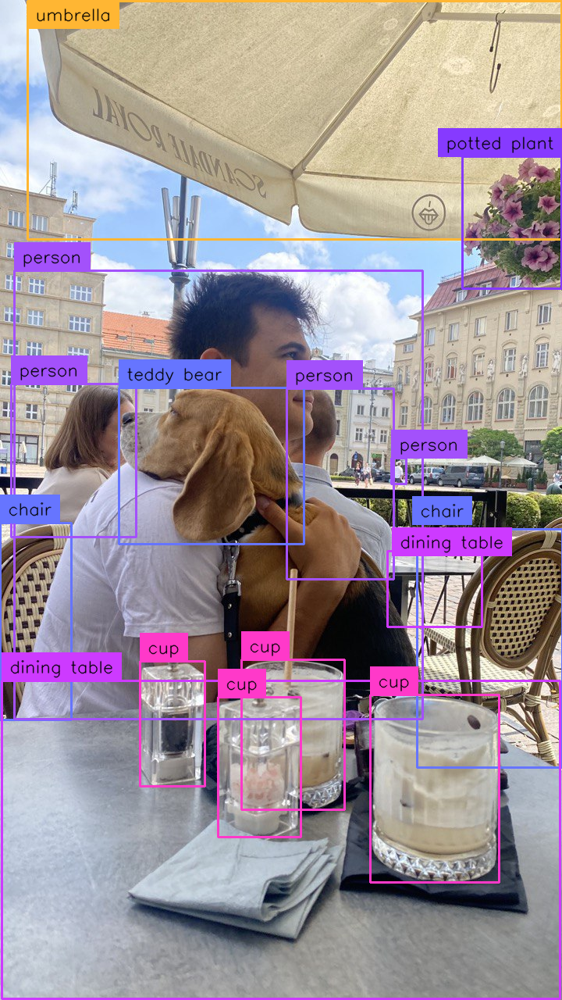

In [ ]:
annotated_image = annotate(image, detections)
annotated_image

## Fine-tune YOLO26 on custom dataset

**NOTE:** When training YOLO26, make sure your data is located in `datasets`. If you'd like to change the default location of the data you want to use for fine-tuning, you can do so through Ultralytics' `settings.json`. In this tutorial, we will use one of the [datasets](https://universe.roboflow.com/liangdianzhong/-qvdww) available on [Roboflow Universe](https://universe.roboflow.com/). When downloading, make sure to select the `yolov11` export format.

In [ ]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

from google.colab import userdata
from roboflow import Roboflow

ROBOFLOW_API_KEY = userdata.get('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

workspace = rf.workspace("roboflow-jvuqo")
project = workspace.project("basketball-player-detection-3-ycjdo")
version = project.version(14)
dataset = version.download("yolo26")

## Custom Training

In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolo26m.pt data={dataset.location}/data.yaml epochs=20 imgsz=640 plots=True

/content
Ultralytics 8.4.2 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/basketball-player-detection-3-14/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, p

**NOTE:** The results of the completed training are saved in `{HOME}/runs/detect/train/`. Let's examine them.

In [ ]:
!ls {HOME}/runs/detect/train/

args.yaml			 results.csv	     val_batch0_labels.jpg
BoxF1_curve.png			 results.png	     val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg    val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg    val_batch1_pred.jpg
BoxR_curve.png			 train_batch290.jpg  val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch291.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch292.jpg  weights
labels.jpg			 train_batch2.jpg


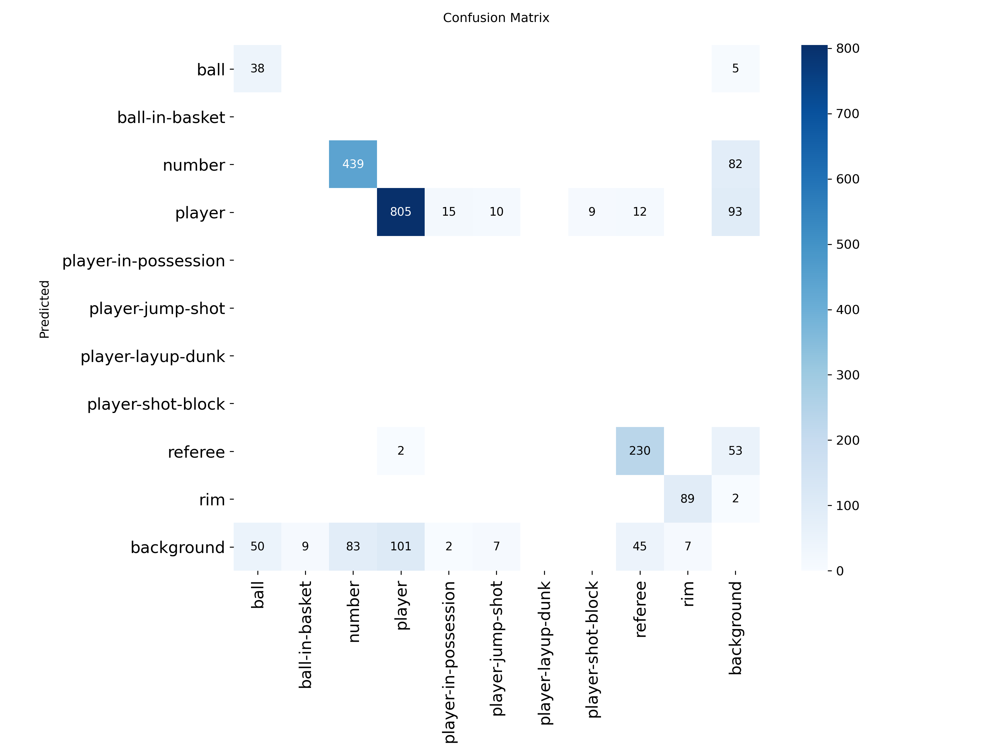

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/confusion_matrix.png', width=600)

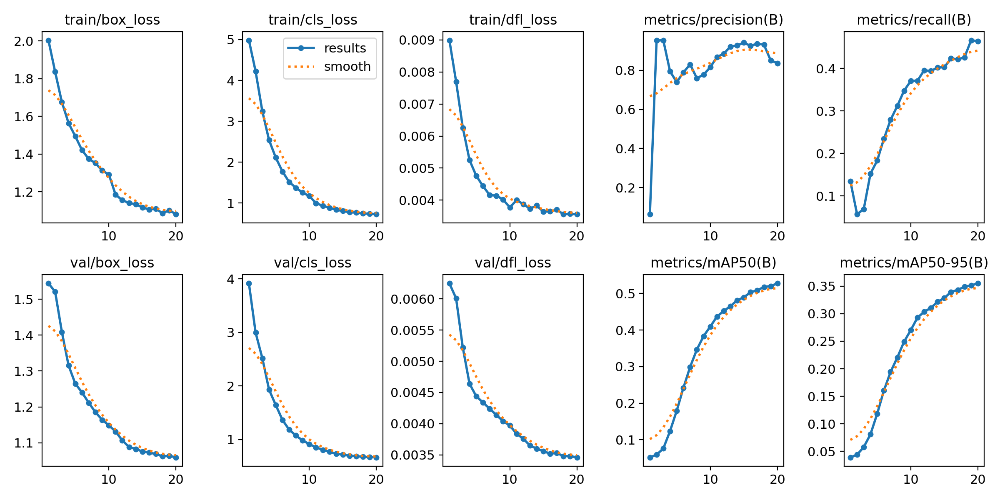

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/results.png', width=600)

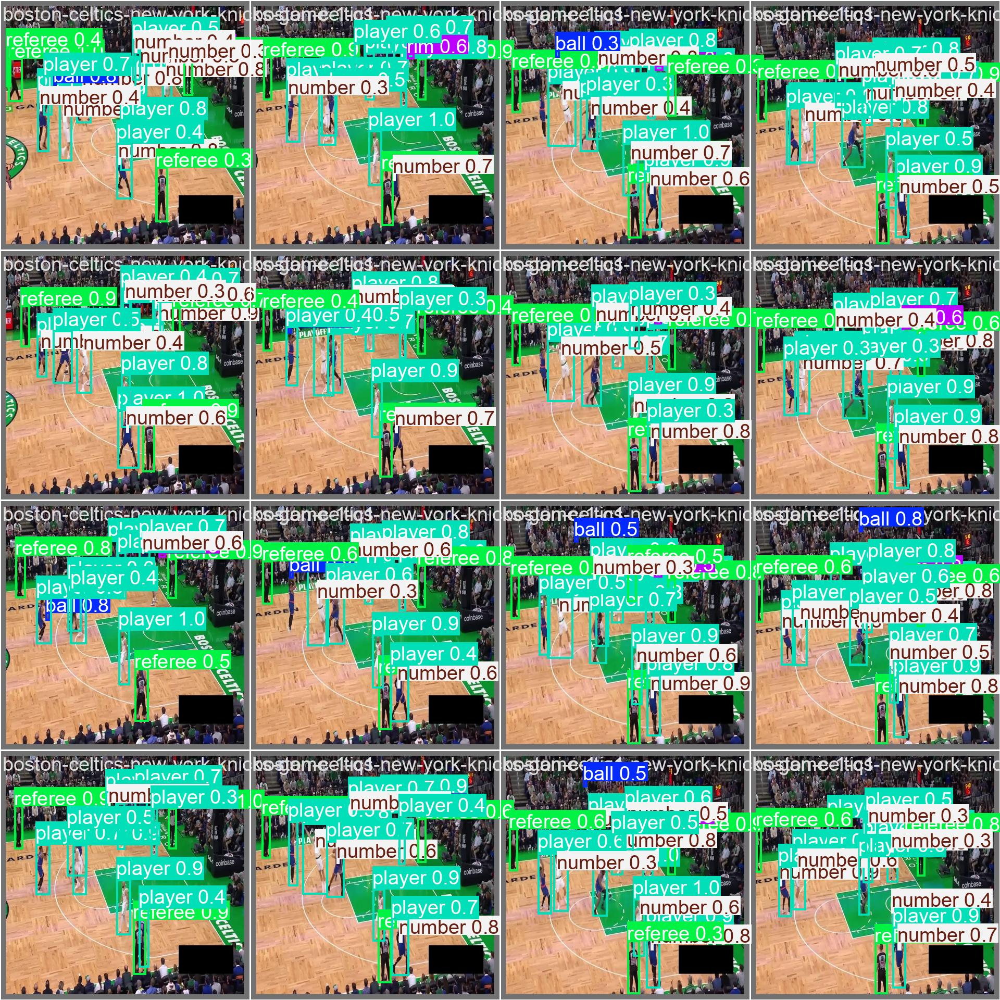

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/val_batch0_pred.jpg', width=600)

## Validate fine-tuned model

In [ ]:
!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml

Ultralytics 8.4.2 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO26m summary (fused): 132 layers, 20,357,162 parameters, 0 gradients, 67.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2953.4±630.4 MB/s, size: 84.8 KB)
val: Scanning /content/datasets/basketball-player-detection-3-14/valid/labels.cache... 96 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 96/96 19.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.1it/s 5.5s
                   all         96       1953      0.841      0.465      0.527      0.355
                  ball         88         88      0.709      0.527      0.621      0.363
        ball-in-basket          9          9          1          0      0.038     0.0076
                number         96        522      0.712      0.872      0.874      0.491
                player         96        908      0.791      0.917      0.935      0.756
  player-in-posse

## Inference with custom model

### CLI

In [ ]:
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt source={dataset.location}/test/images save=True verbose=False

Ultralytics 8.4.2 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO26m summary (fused): 132 layers, 20,357,162 parameters, 0 gradients, 67.9 GFLOPs
Results saved to /content/runs/detect/predict4
💡 Learn more at https://docs.ultralytics.com/modes/predict


### SDK

In [ ]:
from ultralytics import YOLO

model = YOLO(f'{HOME}/runs/detect/train/weights/best.pt')

In [ ]:
import supervision as sv

ds_test = sv.DetectionDataset.from_yolo(
    images_directory_path=f"{dataset.location}/test/images",
    annotations_directory_path=f"{dataset.location}/test/labels",
    data_yaml_path=f"{dataset.location}/data.yaml"
)

In [ ]:
import supervision as sv
from PIL import Image

def annotate(image: Image.Image, detections: sv.Detections) -> Image.Image:
    color = sv.ColorPalette.from_hex([
        "#9999ff", "#3399ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00",
        "#ffff00", "#ff9b00", "#ff8080", "#ff66b2", "#ff66ff", "#b266ff",
    ])

    text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)

    box_annotator = sv.BoxAnnotator(color=color)
    label_annotator = sv.LabelAnnotator(
        color=color,
        text_color=sv.Color.BLACK,
        text_scale=text_scale,
        smart_position=True
    )

    out = image.copy()
    out = box_annotator.annotate(out, detections)
    out = label_annotator.annotate(out, detections)
    out.thumbnail((1000, 1000))
    return out

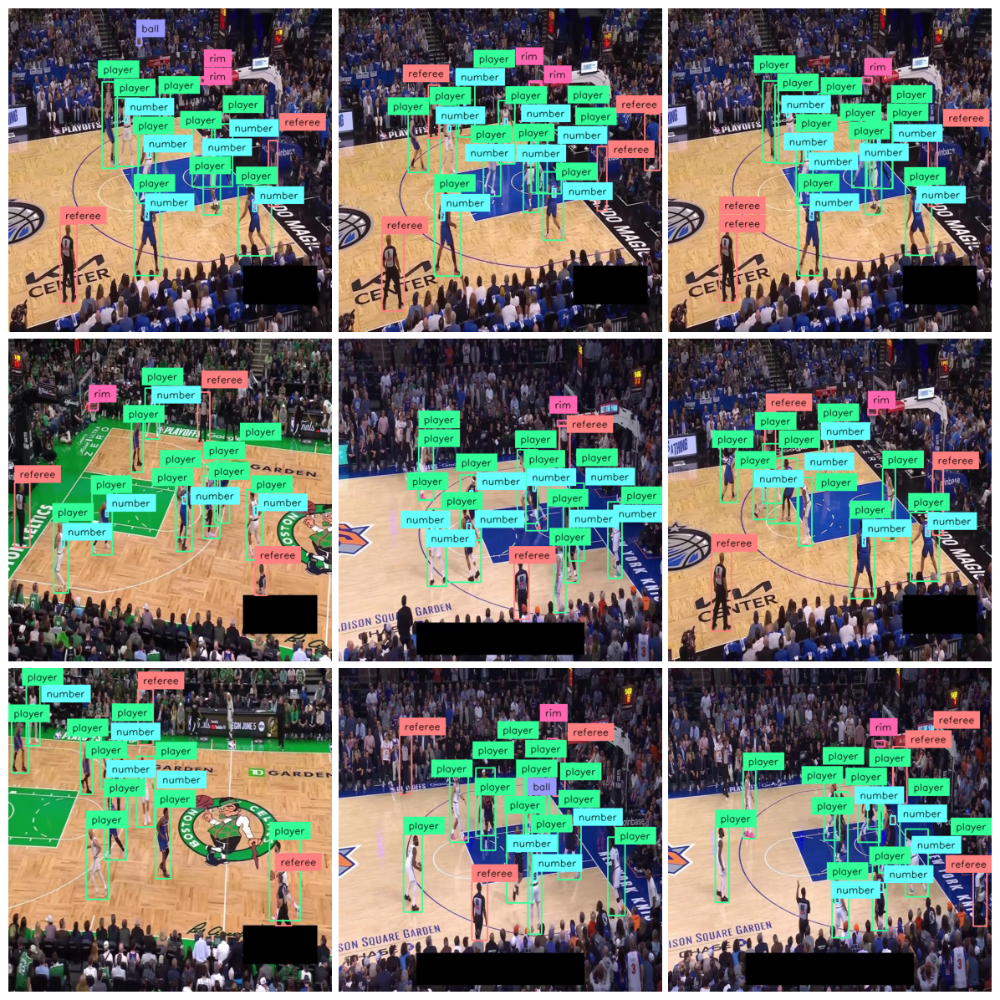

In [ ]:
import random
import matplotlib.pyplot as plt

N = 9
L = len(ds_test)

annotated_images = []

for i in random.sample(range(L), N):
    path, _, annotations = ds_test[i]
    image = Image.open(path)
    result = model.predict(image, verbose=False)[0]
    detections = sv.Detections.from_ultralytics(result)
    annotated_image = annotate(image, detections)
    annotated_images.append(annotated_image)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, img in zip(axes.flat, annotated_images):
    ax.imshow(img)
    ax.axis("off")

plt.subplots_adjust(wspace=0.02, hspace=0.02, left=0.01, right=0.99, top=0.99, bottom=0.01)

plt.show()

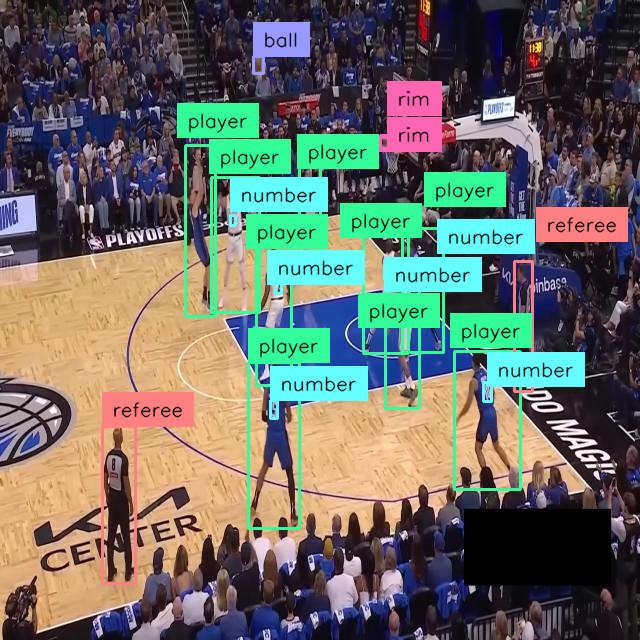

In [ ]:
annotated_images[0]

## Deploy model on Roboflow

Upload the YOLO26 weights to Roboflow Deploy for inference on Roboflow infrastructure built for scale.

In [ ]:
project.version(dataset.version).deploy(model_type="yolo26", model_path=f"{HOME}/runs/detect/train/")

View the status of your deployment at: https://app.roboflow.com/roboflow-jvuqo/basketball-player-detection-3-ycjdo/14
Share your model with the world at: https://universe.roboflow.com/roboflow-jvuqo/basketball-player-detection-3-ycjdo/model/14


## Run inference with a Roboflow hosted model

Load a trained model from Roboflow and run inference.

In [ ]:
!pip install -q inference

In [ ]:
from inference import get_model
from google.colab import userdata

ROBOFLOW_API_KEY = userdata.get('ROBOFLOW_API_KEY')

model_id = project.id.split("/")[1] + "/" + dataset.version
model = get_model(model_id, ROBOFLOW_API_KEY)

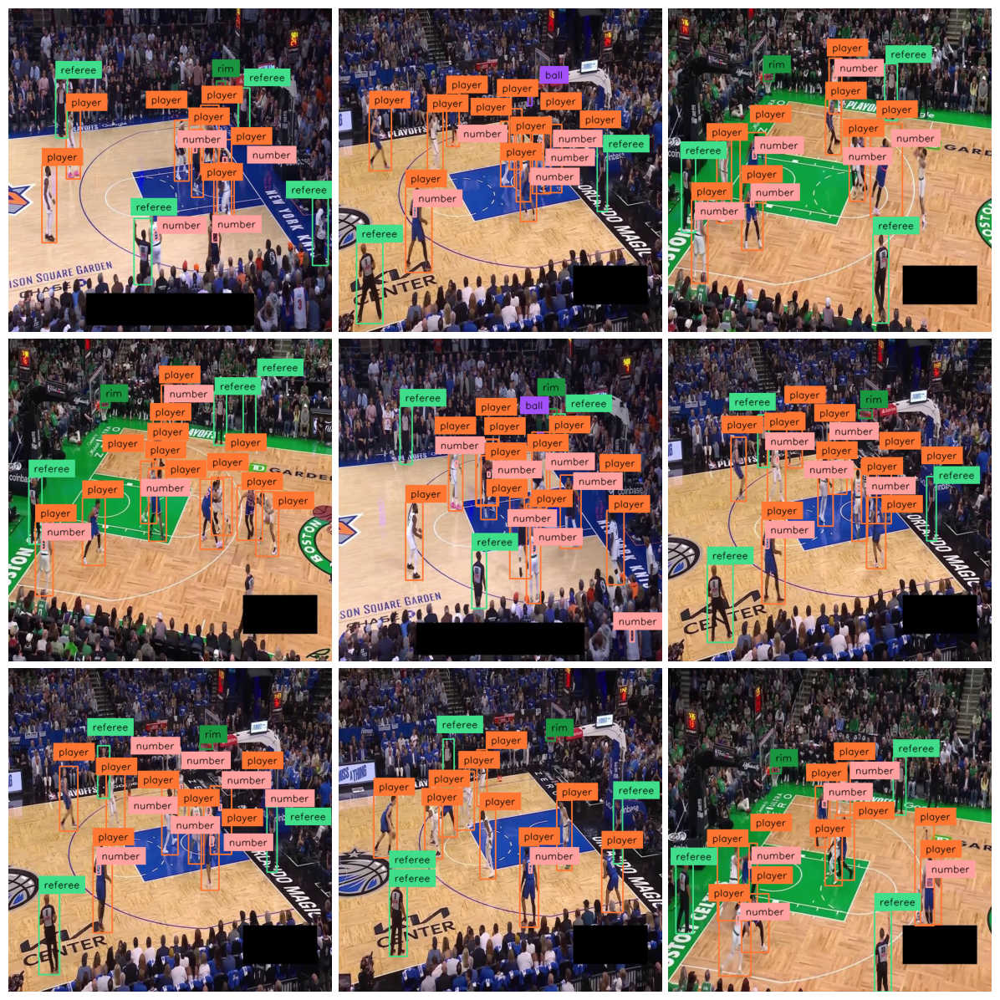

In [ ]:
import random
import matplotlib.pyplot as plt

N = 9
L = len(ds_test)

annotated_images = []

for i in random.sample(range(L), N):
    path, _, annotations = ds_test[i]
    image = Image.open(path)
    result = model.infer(image)[0]
    detections = sv.Detections.from_inference(result)
    annotated_image = annotate(image, detections)
    annotated_images.append(annotated_image)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, img in zip(axes.flat, annotated_images):
    ax.imshow(img)
    ax.axis("off")

plt.subplots_adjust(wspace=0.02, hspace=0.02, left=0.01, right=0.99, top=0.99, bottom=0.01)

plt.show()

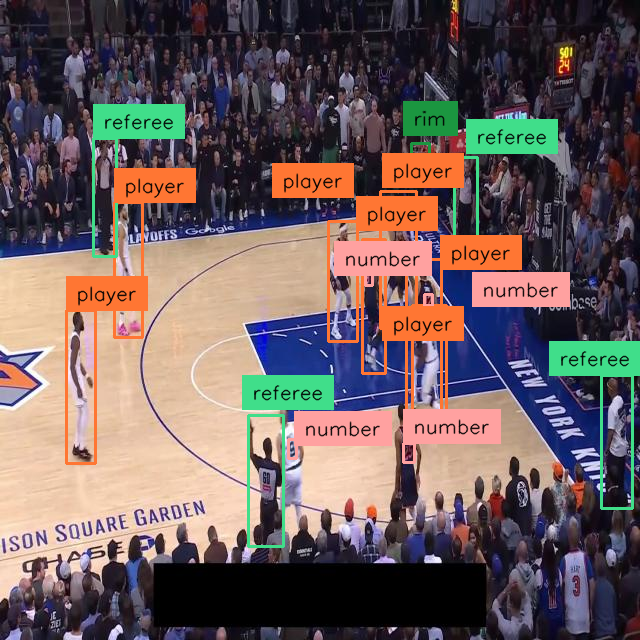

In [ ]:
annotated_images[0]

<div align="center">
  <p>
    Looking for more tutorials or have questions?
    Check out our <a href="https://github.com/roboflow/notebooks">GitHub repo</a> for more notebooks,
    or visit our <a href="https://discord.gg/GbfgXGJ8Bk">discord</a>.
  </p>
  
  <p>
    <strong>If you found this helpful, please consider giving us a ⭐
    <a href="https://github.com/roboflow/notebooks">on GitHub</a>!</strong>
  </p>

</div>